## Plotted SNV frequency trajectories and assign states at each time point using HMM

## 0. General

### 0.1. Load libraries

In [1]:
import os, pandas as pd, numpy as np, random, math
from scipy.special import betainc

In [2]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import matplotlib.gridspec as gridspec

import seaborn as sns

sns.set_theme(style="white", font="Arial")
sns.set_context({'font.size': 10.0, 'axes.labelsize': 12, 'axes.titlesize': 14,
                 'xtick.labelsize': 10, 'ytick.labelsize': 10, 'legend.fontsize': 10,
                 'legend.title_fontsize': None, 'axes.linewidth': 0.8, 'grid.linewidth': 0.8,
                 'lines.linewidth': 1.5, 'lines.markersize': 6.0, 'patch.linewidth': 1.0,
                 'xtick.major.width': 0.5, 'ytick.major.width': 0.5, 'xtick.minor.width': 0.3,
                 'ytick.minor.width': 0.3, 'xtick.major.size': 3.5, 'ytick.major.size': 3.5,
                 'xtick.minor.size': 2.0, 'ytick.minor.size': 2.0,})

plt.rcParams['xtick.bottom'] = True
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial']
plt.rcParams['font.size'] = 12
plt.rcParams['xtick.bottom'] = True
plt.rcParams['ytick.left'] = True


### 0.2. General variables

In [3]:
detection_limit = 0.01

In [4]:
donors = [1,2,3,4]
replicates = ["A", "B", "C"]
passages = list(range(0, 110, 10))
tech_reps = [1,2 ]
populations = ["1A", "1B", "1C", "2A", "2B", "2C", "3A", "3B", "3C", "4A", "4B", "4C"]
segments = ["1-PB2", "2-PB1", "3-PA", "4-HA", "5-NP", "6-NA", "7-M", "8-NS"]

hours_per_passage = 72 #hours
generation_time = 6 #hours > assumption based on Baccam, et al. 2006

In [5]:
#color palette 
segment_cpal = ["#ea5545","#f46a9b", "#ef9b20", "#ede15b", "#87bc45", "#27aeef", "#776efa", "#b33dc6"]
state_cols = {"A": "#aadb48", "P":"#e2903a", "F":"#ca0090", }
state_labels =  {"A":"Ancestral","P": "Polymorphic","F":"Fixed", }
population_cpal = [ "#005fb9", "#58b4e2", "#8ee6ff", "#860041", "#ca0090", "#ff53c0", "#006e00", "#77a908", "#bbe837", "#0000ba", "#5f38ed", "#d49eff" ]


### 0.3. Functions 

#### 0.3.1. Hidden Markov Model

**Input**  
Depth matrix $\mathbf{D}_{M,T}$ where $N$ is the number of alleles and $T$ is the total number of timepoints.  
Allele count matrix $\mathbf{A}_{M,T}$ where $N$ is the number of alleles and $T$ is the total number of timepoints.  
- $M$ = mutations 
- $T$ = timepoints in seasons

For depth and allele count matrices not including unknown AA's or gaps (X)


**States**
- Ancestral: Allele is ancestral state no detectable SNVs have observed.
- Polymorphic: There are one or multiple SNVs are the allele
- Fixed: An SNV has fixed at this allele

In [6]:
def HMM(D, A, a=0.33, ap=0.33, af=0.33,pa=0.33, p=0.33, pf=0.33, fa=0.33, fp=0.33, f=0.33,
        n_iter=100, min_error=1e-3, epsE=0.025, epsF=0.02, p0v= 0.01, p1v=0.01):
        # br=1e-10, er=0.25, dr=1e-5, gr=0.55, fr=0.25, rr=0.3,

    #define states 
    states = {"A":0, "P":1, "F":2}
    L = len(states)

    #get information from A and D 
    M, T = A.shape #get number of mutation (M) and timepoints (T)
    R = D - A # array of alt allele  > tecnically reference

    #intialize p0 and p1 > error probability vectors 
    p0=np.full_like(D, p0v) #probability of observing error in the ancestral state
    p1=np.full_like(D, p1v) #probability of observing error in the fixed state
    Pstate = np.zeros((M,T,L)) # decoding probabilities for each state

    #initiate transition matrix
    Q = np.zeros((T,L,L))
    for t in range(T):
        Q[t,states["A"],:] = np.array([a, pa, fa]) #transtion to ancestral state 
        Q[t,states["P"],:] = np.array([ap, p, fp]) #transtion to polymorphic state 
        Q[t,states["F"],:] = np.array([af, pf, f]) #transtion to fixed state

    #Baum-Welch // Forward-Backward algorithm
    for i in range(n_iter):
        logV = np.zeros((M,T,L)) #observation likelihood // emission probabilities
        
        ancestral_beta = np.clip(betainc(A+1,R+1,2*p0),1e-300,1) #+1 for safety > does not change results
        logV[:,:,states['A']] = (D>0.5)*(np.log(ancestral_beta)-np.log(2*p0)) 

        fixed_beta = np.clip(betainc(R+1,A+1,2*p1),1e-300,1)
        logV[:,:,states['F']] = (D>0.5)*(np.log(fixed_beta)-np.log(2*p1))

        logV[:,:,states['P']] = (D>0.5)*(0.0) #polymorphic

        #normalize observation likelihood across all states
        logVmax = logV.max(axis=2)
        for l in range(L):
            logV[:,:,l]-=logVmax
        V = np.exp(logV)

        ## initialize F and B
        F = np.zeros((M,T,L)) # forward probability table
        B = np.zeros((M,T,L)) # backward probability table
        
        # All mutations start in ancestral state at timepoint = 0
        F[:,0,states['A']] = 1.
        
        # mutations can end up in any state
        B[:,T-1,states['A']] = 1.0/(L-1)
        B[:,T-1,states['P']] = 1.0/(L-1)
        B[:,T-1,states['F']] = 1.0/(L-1)

        #actual Baum-Welch // Forward-Backward algorithm
        for t in range(1,T): #forward
            F[:,t,:] = V[:,t,:]*(np.dot(F[:,t-1,:], np.transpose(Q[t-1,:,:])))
            sum_F = F[:,t,:].sum(axis=1) + (F[:,t,:].sum(axis=1) < 1e-12)
            F[:,t,:] /= np.outer(sum_F, np.ones(L))

        for t in reversed(range(T-1)): #backward
            B[:,t,:] =  np.dot(B[:,t+1,:]*V[:,t+1,:], Q[t,:,:])
            sum_B = B[:,t,:].sum(axis=1) + (B[:,t,:].sum(axis=1) < 1e-12)
            B[:,t,:] /= np.outer(sum_B, np.ones(L))
         
        #compute posterior states    
        FB = F * B
        denom = FB.sum(axis=2, keepdims=True)
        denom = np.where(denom < 1e-300, 1.0, denom)
        Pstate = FB / denom     

        # Update the error probability vectors
        aen = (A * Pstate[:, :, states["A"]]).sum(axis=1)  # ancestral error numerators
        aed = (D * Pstate[:, :, states["A"]]).sum(axis=1)  # ancestral error denominators
        den = (R * Pstate[:, :, states["F"]]).sum(axis=1)  # derived error numerators
        ded = (D * Pstate[:, :, states["F"]]).sum(axis=1)  # derived error denominators

        # Add a small positive value to the denominators to avoid division by zero
        aed += 1e-12
        ded += 1e-12

        # Use parentheses to fix the boolean condition
        p0 = np.outer(np.clip(aen / (aed + (aed < 1e-12)), min_error, epsE), np.ones(T))
        p1 = np.outer(np.clip(den / (ded + (ded < 1e-12)), min_error, epsF), np.ones(T))

    #Viterbi algorithm // infer most likely sequence of states
    mlt = np.zeros((M,T,L)) #max likelihood table
    spt = np.zeros((M,T,L)) #state pointer table

    mlt[:,0,:] = F[:,0,:] #all mutations state in ancestral state at timepoint = 0
    for t in range(1,T):
        nl = mlt[:,t-1,None,:]*Q[None,t-1,:,:] #new likelihoods
        mlt[:,t,:] = nl.max(axis=2)
        spt[:,t-1,:] = nl.argmax(axis=2)

        mlt[:,t,:] *= V[:,t,:]

        scale = np.outer(np.clip(mlt[:,t,:].max(axis=1),1e-300,1e300), np.ones(L))
        mlt[:,t,:] /=scale

    #follow path back
    Ls = np.zeros((M,T), dtype=np.int32)
    Ls[:,-1] = mlt[:,-1,:].argmax(axis=1)
    for t in reversed(range(1,T)):
        for m in range(M):
            Ls[m,t-1] = spt[m,t-1,Ls[m,t]]

    S = pd.DataFrame(Ls).replace({v:s for s,v in states.items()}).to_numpy()   
    return Pstate, Ls,S, p0, p1

#estimate transition rates
def manual_classification(freqs):

    states = []
    for i, f in enumerate(freqs):
        if i == 0:
            state = "A"
        elif f <= 0.01:
            state = "A"
 
        elif f>= 0.95:
            state = "F"   
        else:
            state = "P"  
        states.append(state)
        

    return states

def estimate_transition_probability(manual_states):
    states = ["A", "P","F"]
    possible_transitions = ["A", "AP", "AF", "P", "PA", "PF", "F", "FP", "FA"]

    transition_count = np.zeros((3,3))
    for i, s1 in enumerate(states):
        for j, s2 in enumerate(states):
            #if transition is possible state with pseudo count +1 
            if s1==s2:
                transition_count[i,j] = 1
            elif s1+s2 in possible_transitions:
                transition_count[i,j] = 1

    #add observed count to transition counts
    for sl in manual_states:
        for i, s in enumerate(sl[:-1]):
            si = states.index(s)
            ts = sl[i+1]
            tsi = states.index(ts)
            if s==ts:
                transition_count[si, tsi] +=1
            elif s+ts in possible_transitions:
                transition_count[si, tsi] +=1

    #get transitions probabilities
    transition_probability = np.zeros((3,3))
    for i, row in enumerate(transition_count):
        s = sum(row)
        for j, v in enumerate(row):
            transition_probability[i, j] = v/s

    return transition_probability

def get_transition_rates(transition_probability):
    a, ap, af = transition_probability[0,0], transition_probability[0,1], transition_probability[0,2]
    pa, p, pf = transition_probability[1,0], transition_probability[1,1], transition_probability[1,2]
    fa, fp, f = transition_probability[2,0], transition_probability[2,1], transition_probability[2,2]

    return a, ap, af, pa, p, pf, fa, fp, f 

def determine_observations(states,timepoints):
    '''determine when a mutation was observed based on the states'''
    observed_states,observation_timepoints = [], []
    observed_state, observation_period = [], []
    for i, state in enumerate(states):
        if state != "A":
            observed_state.append(state)
            observation_period.append(timepoints[i])
        else:
            if len(observed_state) > 0:
                observed_states.append(observed_state)
                observation_timepoints.append(observation_period)
                observed_state, observation_period = [], []
    if len(observed_state) > 0:
        observed_states.append(observed_state)
        observation_timepoints.append(observation_period)
    return observed_states, observation_timepoints

## 1. Frequency trajectories 

In [7]:
#load data
#load snv summary 
snv_summary = pd.read_csv("../results/snv_summary.csv", keep_default_na=False, na_values=[""]).set_index(["population", "refname", "nucpos", "snv"]).sort_index()

#create overview of non-synonymous SNVs (for convienence)
non_synonymous_dict = {segment:[] for segment in segments}
for i in snv_summary[snv_summary["non_synonymous"]==True].index.droplevel(0):
    non_synonymous_dict[i[0]].append(i[-1])
    
#load trajectories to see assignment 
trajectories = pd.read_csv("../results/snv_trajectories.csv").set_index(["population", "refname", "nucpos", "snv"]).sort_index()
trajectories = trajectories.rename(columns={c:int(c) for c in trajectories.columns})

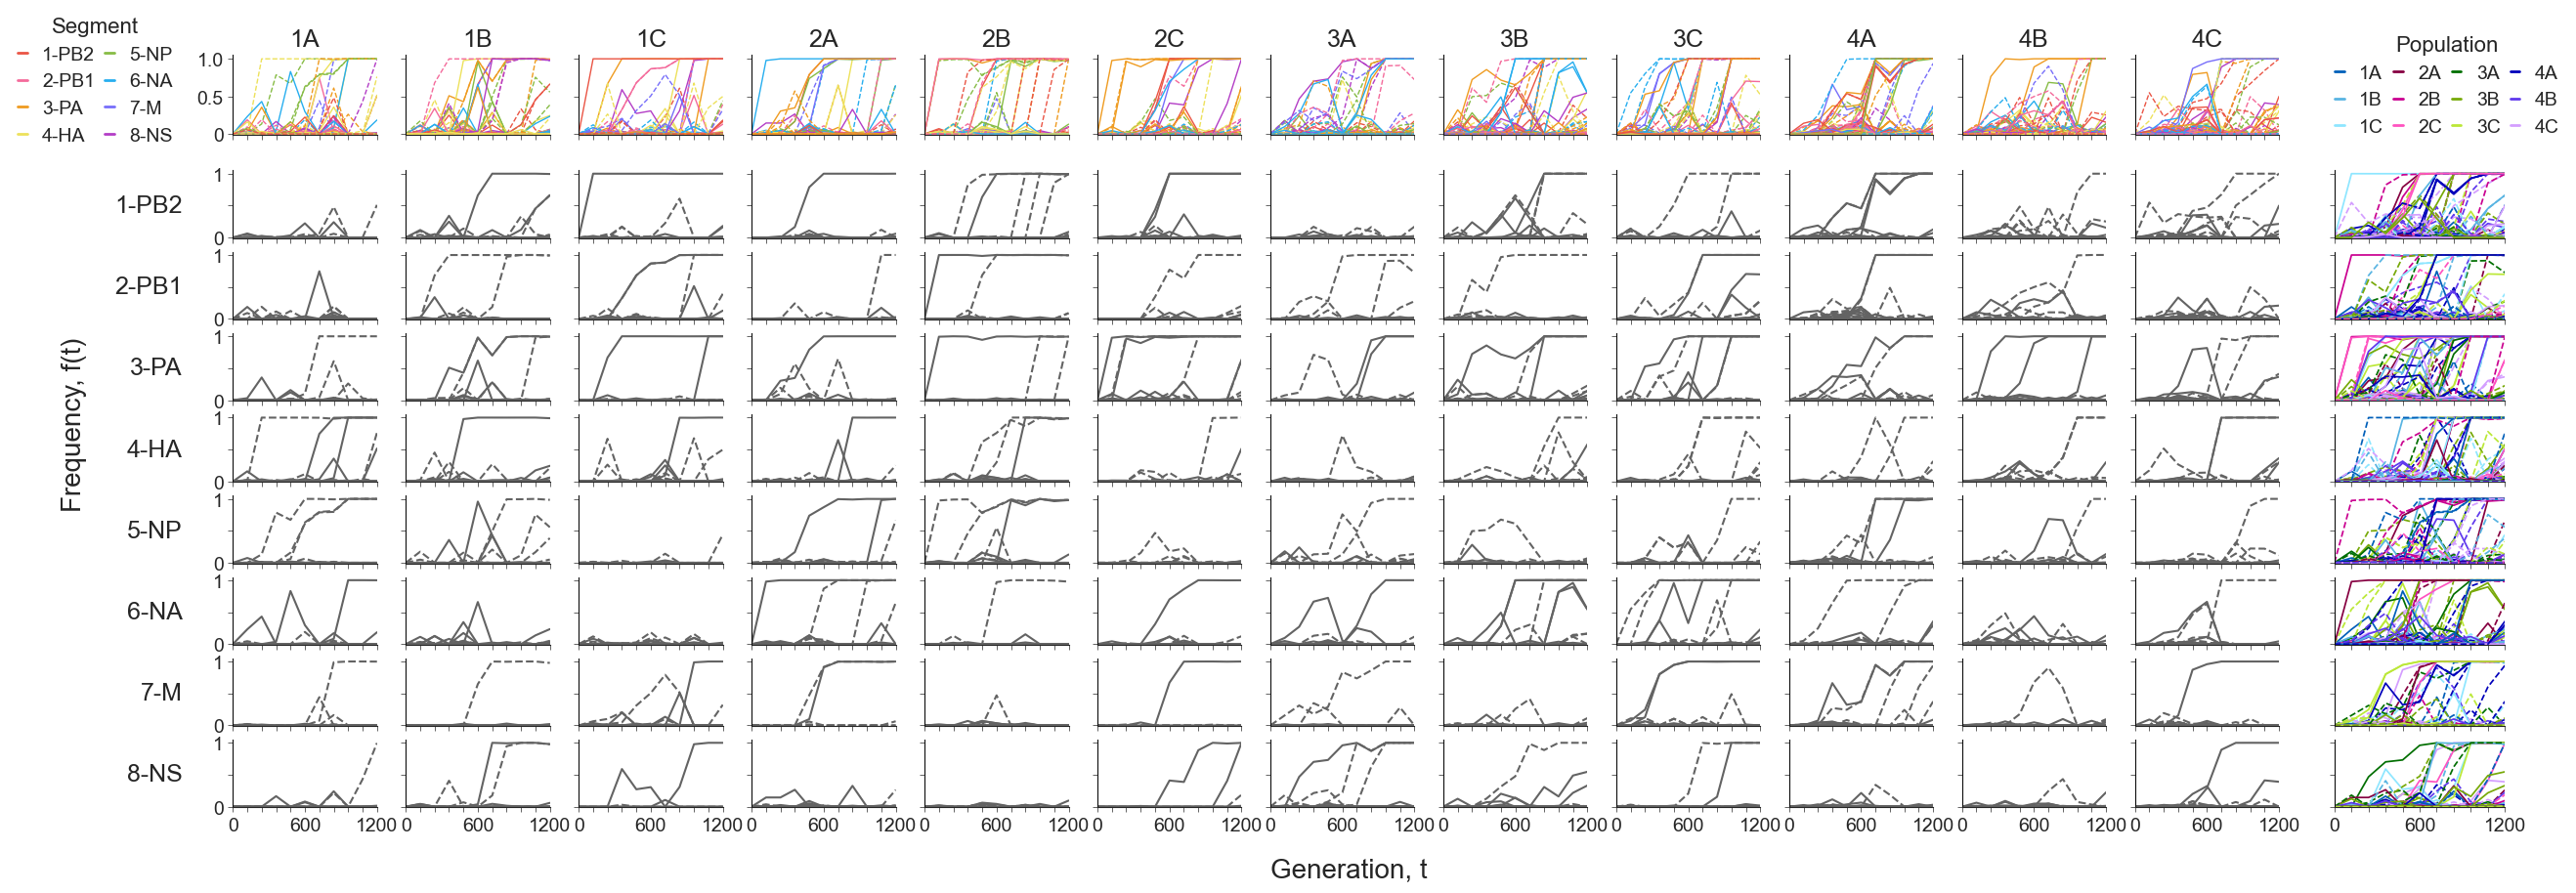

In [8]:
fig = plt.figure(figsize=(12*2.5, 8*1.25))
gs = gridspec.GridSpec(2,2, width_ratios=[12,1], height_ratios=[1,8], wspace=0.05, hspace=0.1)

gsi0 = gridspec.GridSpecFromSubplotSpec(1, len(populations), subplot_spec=gs[0,0])
gsi1 = gridspec.GridSpecFromSubplotSpec(1, len(populations), subplot_spec=gs[1,0])

#prep legends
segment_legend_elements = []#[Line2D([0], [0], color='white', label="segment", linewidth=0,)]
for i , s in enumerate(segments):
    # segment_legend_elements.append(Line2D([0], [0], color=segment_cpal[i], label=s.split("-")[-1], linewidth=2,  ))
    segment_legend_elements.append(Line2D([0], [0], color=segment_cpal[i], label=s, linewidth=2,  ))
    
    
type_legend_elements=[]#[Line2D([0], [0], color='white', label="type", linewidth=0)]
type_legend_elements.append(Line2D([0], [0], color='darkgrey', label="non-\nsynonymous", linewidth=1,))
type_legend_elements.append(Line2D([0], [0], color='darkgrey', label="synonymous", linewidth=1, linestyle='--'))

population_legend_elements = []#[Line2D([0], [0], color='white', label="population", linewidth=0,)]
for i, population in enumerate(populations):
    population_legend_elements.append(Line2D([0], [0], color=population_cpal[i], label=population, linewidth=2,  ))

for i, population in enumerate(populations):
    gsij = gridspec.GridSpecFromSubplotSpec(len(segments), 1, subplot_spec=gsi1[i])
    
    pop_ax = fig.add_subplot(gsi0[i])
    idx_list = [trajectories.index.tolist()[_][1:] for _, pop in enumerate(trajectories.index.get_level_values(0)) if pop == population]
    random.shuffle(idx_list)
    
    for (refname, nucpos, snv) in idx_list:
        timepoints = passages 
        frequencies = trajectories.loc[(population, refname, nucpos, snv), :].dropna().values
        
        pop_ax.plot(timepoints, frequencies, c=segment_cpal[segments.index(refname)], lw=1, alpha=1, ls='-' if snv in non_synonymous_dict[refname] else '--')
        
    pop_ax.text(50, 1.1, population, va="bottom", ha="center", size=18)
    pop_ax.spines[['top','right']].set_visible(False)
    pop_ax.set_xlim(-0, timepoints[-1])
    pop_ax.axvline(0, color="black", zorder=100, lw=0.5)
        
    pop_ax.set_ylim(-0.01,1.05)
    pop_ax.set_yticks([0, 0.5, 1.0])
    pop_ax.set_xticks([0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100])
    pop_ax.set_xticklabels([])
    
    if i >0 :
        pop_ax.set_yticklabels([])
    if i == 0:
        pop_ax.set_yticklabels([0, 0.5, 1.0], size=14)
        leg = pop_ax.legend(handles=segment_legend_elements, title="Segment", loc='upper right', bbox_to_anchor=(-.3,1.7), ncols =2, fontsize=14, handlelength=0.5,title_fontsize=16,
                            edgecolor=None, frameon=False, columnspacing=0.5)
        
    
        
    for j, refname in enumerate(segments):
        ax= fig.add_subplot(gsij[j])
        for (rn, nucpos, snv) in idx_list:
            if rn != refname:
                continue
            timepoints = passages
            frequencies = trajectories.loc[(population, refname, nucpos, snv), :].dropna().values
            
            ax.plot(timepoints, frequencies, c="#636363", lw=1.5, alpha=1, ls='-' if snv in non_synonymous_dict[refname] else '--')
            
        ax.spines[['top','right']].set_visible(False)
        ax.set_xlim(-0, timepoints[-1])
        ax.axvline(0, color="black", zorder=100, lw=0.5)
        
        ax.set_ylim(-0.01,1.05)
        ax.set_yticks([0, 0.5, 1.0])
        ax.set_xticks([0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100])
        if i>0:
            ax.set_yticklabels([])
        else:
            ax.set_yticklabels([0, '', 1], size=14)
        
        if i == 0:
            # ax.text(-30, 0.5, refname.split("-")[-1], rotation=90, va="center", ha="right", size=16)
            ax.text(-35, 0.5, refname, va="center", ha="right", size=18)
        
            
        if j < len(segments)-1:
            ax.set_xticklabels([])
        else:
            ax.set_xticklabels([0, "", "", "", "", int((50*hours_per_passage)/generation_time), 
                                "", "", "", "", int((100*hours_per_passage)/generation_time)], size=14)
             
        if i == 0 and j == 2:
            ax.text(-110, 1, "Frequency, f(t)", size=20, rotation=90, ha="center", va="top")
        if j == 7 and i == 6:
            ax.text(0, -0.8, "Generation, t", size=20, ha="left", va="top")
            
        # if i == len(populations)-1 and j == 0:
        #     leg = ax.legend(handles=type_legend_elements, title="SNV type", loc='upper left', bbox_to_anchor=(2.2,3.85), ncols =1, fontsize=10, handlelength=1,
        #                     edgecolor=None, frameon=False, columnspacing=0.5)
                     
plot_trajec = trajectories.reset_index().set_index(["refname", "population", "nucpos", "snv"]).sort_index()
gsi2 = gridspec.GridSpecFromSubplotSpec(len(segments), 1, subplot_spec=gs[1,1 ])
for i, refname in enumerate(segments):
    ax = fig.add_subplot(gsi2[i])
    df = plot_trajec.loc[refname]
    idx_list =df.index.tolist()
    random.shuffle(idx_list)
    
    for (population, nucpos, snv) in idx_list:
        
        freqs = [f for f in df.loc[(population, nucpos, snv)] if not pd.isna(f)]
        
        timepoints = passages
        donor, replicate = population
        
        ax.plot(timepoints, freqs, c=population_cpal[populations.index(population)], lw=1.25, alpha=1, ls='-' if snv in non_synonymous_dict[refname] else '--')
        
    ax.spines[['top','right']].set_visible(False)
    ax.set_xlim(-0, timepoints[-1])
    ax.axvline(0, color="black", zorder=100, lw=0.5)
    
    ax.set_ylim(-0.01,1.05)
    ax.set_yticks([0, 0.5, 1.0])
    ax.set_xticks([0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100])
    if i != len(segments)-1:
        ax.set_xticklabels([])
    else:
        ax.set_xticklabels([0, "", "", "", "", int((50*hours_per_passage)/generation_time), 
                            "", "", "", "", int((100*hours_per_passage)/generation_time)], size=14)
            
    ax.set_yticklabels([])
    if i == 0:
        leg = ax.legend(handles=population_legend_elements, loc='upper left',  title="Population", title_fontsize=16,
                        bbox_to_anchor=(-0.1,3.25), ncols =4, fontsize=14, handlelength=0.5, edgecolor=None, frameon=False, 
                        columnspacing=0.5)
        
fig.savefig("../figures/fig1_frequency_trajectories.svg", dpi=300,bbox_inches='tight')
fig.savefig("../figures/fig1_frequency_trajectories.png", dpi=300,bbox_inches='tight')    

**Figure 1 The allele frequency trajectories of all de novo single nucleotide variants (SNVs) detected in the experimental populations.** Top row displays the allele frequency trajectories per population, with each trajectory coloured by the segment. Right most column displays the SNV trajectories per segment, with the trajectory coloured by the population. The remaining rows and columns display the trajectories per population per segment. Solid and dotted lines indicate non-synonymous and synonymous SNVs, respectively.  

## 2. Classification of SNV trajectories states using the HMM

### 2.1. prep data

In [9]:
coverage_dir = "../results/nucleotide_coverage"

In [10]:
#generate depth and alternate allele count matrices for the trajectories
D, A = [], []

#tested random shuffling as a sanity check > no effect 
rando = np.random.default_rng(seed=918237491823749182374918237491823749182374918237491823749182374918237491823749182374918237491823793) 
shuffled_snvs = trajectories.index.tolist()
# rando.shuffle(shuffled_snvs)

for (population, refname, nucpos, snv) in shuffled_snvs:


    nucpos, base = int(snv[1:-1]), snv[-1]
    d, a = [], []
    
    #starting with starting virus 
    depths, allele_counts = [], []
    #combining observation of the technical replicates
    #testing this before > combined, or seperate both give same state assignment > so combining for speed
    for tech_rep in tech_reps:
        coverage_file = os.path.join(coverage_dir, f"nuc_coverage_stock_{tech_rep}.csv")
        coverage = pd.read_csv(coverage_file, keep_default_na=False, na_values=[""]).fillna(0)
        
        coverage = coverage.set_index(["refname", "nucpos"])
        depths.append(coverage.loc[(refname, nucpos), "coverage"])
        allele_counts.append(coverage.loc[(refname, nucpos), base])
        
    d.append(np.sum(depths))
    if np.mean(allele_counts)/np.mean(depths) >= detection_limit and allele_counts[0]/depths[0]>=detection_limit and allele_counts[1]/depths[1]>=detection_limit and all(d>500 for d in depths):
        a.append(np.sum(allele_counts))
    else:
        a.append(0)
    
    #actual timepoint measurements
    for timepoint in passages[1:]: 
        depths, allele_counts = [], []
        for tech_rep in tech_reps:
            coverage_file = os.path.join(coverage_dir, f"nuc_coverage_P{timepoint}-{population}_{tech_rep}.csv")
            coverage = pd.read_csv(coverage_file, keep_default_na=False, na_values=[""]).fillna(0)
            
            coverage = coverage.set_index(["refname", "nucpos"])
            depths.append(coverage.loc[(refname, nucpos), "coverage"])
            allele_counts.append(coverage.loc[(refname, nucpos), base])
            
        d.append(np.sum(depths))
        if np.mean(allele_counts)/np.mean(depths) >= detection_limit and allele_counts[0]/depths[0]>=detection_limit and allele_counts[1]/depths[1]>=detection_limit and all(d>500 for d in depths):
            a.append(np.sum(allele_counts))
        else:
            a.append(0)

    D.append(np.array(d))
    A.append(np.array(a))
    


### 2.2. estimate transition probabilities and run HMM

In [11]:
#determine the transition rates > via 'manual-like' state assignment
sample_size = math.ceil(0.5* len(trajectories))
subsample = random.sample(shuffled_snvs, sample_size)

manual_assigned_states = []
for idx in subsample:
    trajec = trajectories.loc[[idx], :].dropna(axis=1).values[0]
    
    states = manual_classification(trajec)
    manual_assigned_states.append(states)

transition_probability = estimate_transition_probability(manual_assigned_states)
a, ap, af, pa, p, pf, fa, fp, f = get_transition_rates(transition_probability)

Pstate, Ls,S, p0, p1 = HMM(np.array(D), np.array(A), a=a, ap=ap, af=af, pa=pa, p=p, pf=pf, fa=fa, fp=fp, f=f, n_iter=1000)

HMM_states = []
for i, (population, refname, nucpos, snv) in enumerate(shuffled_snvs):
    states = []
    for passage in passages:
        if passage not in timepoints:
            states.append(np.NaN)
        else:
            states.append(S[i][timepoints.index(passage)])
    HMM_states.append([population, refname, nucpos, snv]+states)

HMM_states = pd.DataFrame.from_records(HMM_states, columns=["population", 'refname', "nucpos", "snv"]+passages).set_index(["population", 'refname', "nucpos", "snv"]).sort_index()


### 2.3. Visualize state assignment 

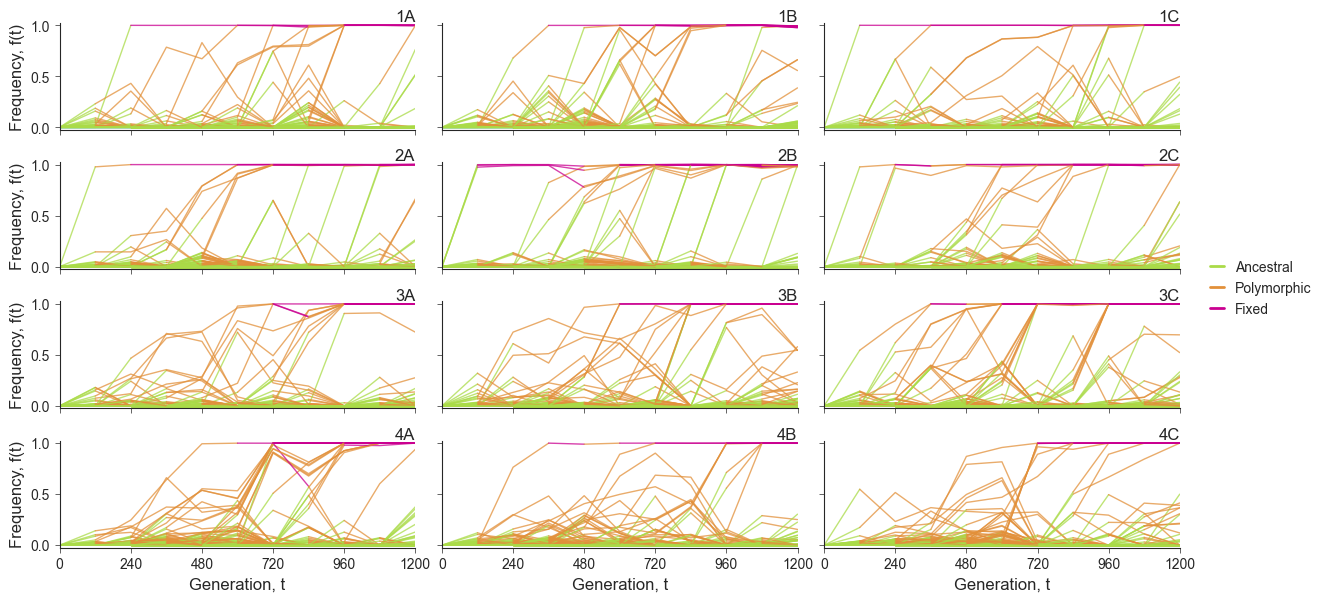

In [12]:
#plot
fig, axes = plt.subplots(len(donors), len(replicates), figsize=((14,7)))
plt.subplots_adjust(left=0.1,bottom=0.1, right=0.9, top=0.85, wspace=0.075, hspace=0.3)

for i, donor in enumerate(donors):
    for j, replicate in enumerate(replicates):
        population = f"{donor}{replicate}"
        ax = axes[i,j]

        idx_list = [trajectories.index.tolist()[_][1:] for _, pop in enumerate(trajectories.index.get_level_values(0)) if pop == population]
        
        for (refname, nucpos, snv) in idx_list:
            timepoints = passages
            frequencies = trajectories.loc[(population, refname, nucpos, snv), :].dropna().values
            # if any(f>0.05 for f in frequencies):
            #     continue
            states = HMM_states.loc[(population, refname, nucpos, snv), :].dropna().values

            if len(set(states))==1:
                ax.plot(timepoints, frequencies, c=state_cols[states[0]], lw=1., alpha=0.75 )
            else:
                si = 0
                while si < len(states)-1:
                    for k, s in enumerate(states[si:], start=si):
                        if s != states[si]:
                            break

                    ax.plot(timepoints[si:k+1], frequencies[si:k+1], c=state_cols[states[si]], lw=1., alpha=0.75)
                    si = k
        #cosmetics
        ax.set_ylim(-0.025,1.025)
        ax.set_xlim(passages[0], passages[-1])
        ax.spines[['top','right']].set_visible(False)

        if j != 0:
            ax.set_yticklabels('')
        else:
            ax.set_ylabel("Frequency, f(t)", size=12)
        ax.set_xticks([0,20,40,60,80,100])
        if i != len(donors)-1:
            ax.set_xticklabels("")
            
        else:
            ax.set_xticklabels([int((p*hours_per_passage)/generation_time) for p in [0,20,40,60,80,100]])
            
            ax.set_xlabel("Generation, t", size=12)

        ax.text(passages[-1], 1.01, population, ha="right", va="bottom")

legend_elements = []
for state, label in state_labels.items():
    legend_elements.append(Line2D([0], [0], color=state_cols[state], label=label, linewidth=2,  ))

leg = axes[2,2].legend(handles=legend_elements, loc='upper left', bbox_to_anchor=(1.05,1.5), ncols =1, fontsize=10, handlelength=1, edgecolor=None, ncol=1, columnspacing=1)
leg.get_frame().set_linewidth(0.0)


Timepoint/generation/passage at which the color changes indicates transition for state X to state Y, where the color corresponds to the assigned states

### 2.4. Sensitivity analyis
Sensitivity analysis to see if subset size used to estimated the initial transitions probablities matters

Text(0.5, 0.34, 'Subsampling 50% of SNVs for initial transition probabilities')

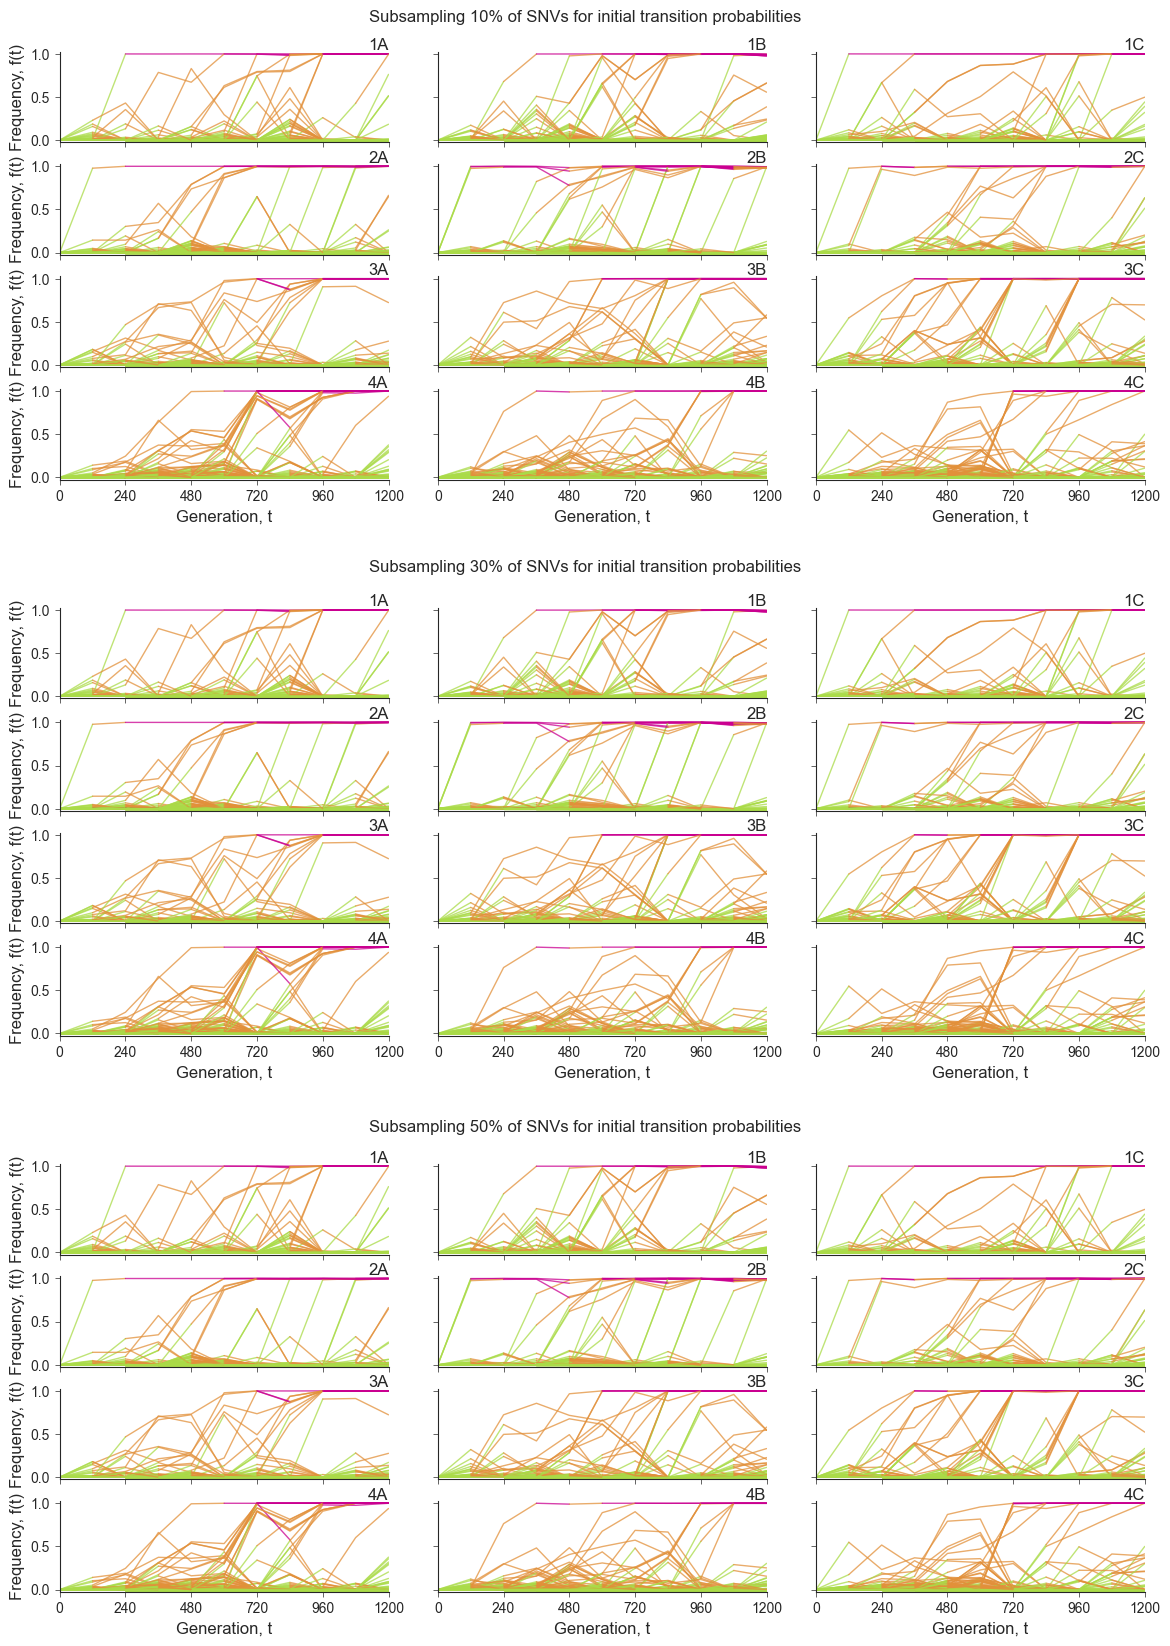

In [13]:
#determine the transition rates > via 'manual-like' state assignment
subsamplesizes = [0.1, 0.3, 0.5]

fig = plt.figure(figsize=((14,20)))
gs = gridspec.GridSpec(3, 1, wspace=0.25, hspace=.3)

for k, subsize in enumerate(subsamplesizes):
    gsi = gridspec.GridSpecFromSubplotSpec(len(donors), len(replicates), wspace=0.15, hspace=0.24, subplot_spec=gs[k])
    
    sample_size = math.ceil(subsize* len(trajectories))
    subsample = random.sample(shuffled_snvs, sample_size)

    manual_assigned_states = []
    for idx in subsample:
        trajec = trajectories.loc[[idx], :].dropna(axis=1).values[0]
        
        states = manual_classification(trajec)
        manual_assigned_states.append(states)

    transition_probability = estimate_transition_probability(manual_assigned_states)
    a, ap, af, pa, p, pf, fa, fp, f = get_transition_rates(transition_probability)

    Pstate, Ls,S, p0, p1 = HMM(np.array(D), np.array(A), a=a, ap=ap, af=af, pa=pa, p=p, pf=pf, fa=fa, fp=fp, f=f, n_iter=1000)

    HMM_states_sens = []
    for i, (population, refname, nucpos, snv) in enumerate(shuffled_snvs):
        states = []
        for passage in passages:
            if passage not in timepoints:
                states.append(np.NaN)
            else:
                states.append(S[i][timepoints.index(passage)])
        HMM_states_sens.append([population, refname, nucpos, snv]+states)
    HMM_states_sens = pd.DataFrame.from_records(HMM_states_sens, columns=["population", 'refname', "nucpos", "snv"]+passages).set_index(["population", 'refname', "nucpos", "snv"]).sort_index()
    
        
    for i, donor in enumerate(donors):
        for j, replicate in enumerate(replicates):
            population = f"{donor}{replicate}"
            ax = fig.add_subplot(gsi[i,j])
            idx_list = [trajectories.index.tolist()[_][1:] for _, pop in enumerate(trajectories.index.get_level_values(0)) if pop == population]
            
            for (refname, nucpos, snv) in idx_list:
                timepoints = passages
                frequencies = trajectories.loc[(population, refname, nucpos, snv), :].dropna().values
                # if any(f>0.05 for f in frequencies):
                #     continue
                states = HMM_states_sens.loc[(population, refname, nucpos, snv), :].dropna().values

                if len(set(states))==1:
                    ax.plot(timepoints, frequencies, c=state_cols[states[0]], lw=1., alpha=0.75 )
                else:
                    si = 0
                    while si < len(states)-1:
                        for k, s in enumerate(states[si:], start=si):
                            if s != states[si]:
                                break

                        ax.plot(timepoints[si:k+1], frequencies[si:k+1], c=state_cols[states[si]], lw=1., alpha=0.75)
                        si = k
            #cosmetics
            ax.set_ylim(-0.025,1.025)
            ax.set_xlim(passages[0], passages[-1])
            ax.spines[['top','right']].set_visible(False)

            if j != 0:
                ax.set_yticklabels('')
            else:
                ax.set_ylabel("Frequency, f(t)", size=12)
            ax.set_xticks([0,20,40,60,80,100])
            if i != len(donors)-1:
                ax.set_xticklabels("")
                
            else:
                ax.set_xticklabels([int((p*hours_per_passage)/generation_time) for p in [0,20,40,60,80,100]])
                
                ax.set_xlabel("Generation, t", size=12)

            ax.text(passages[-1], 1.01, population, ha="right", va="bottom")

fig.text(0.5, 0.895,  f"Subsampling {int(subsamplesizes[0]*100)}% of SNVs for initial transition probabilities", ha="center")
fig.text(0.5, 0.62,  f"Subsampling {int(subsamplesizes[1]*100)}% of SNVs for initial transition probabilities", ha="center")
fig.text(0.5, 0.34, f"Subsampling {int(subsamplesizes[2]*100)}% of SNVs for initial transition probabilities", ha="center")





### 2.5. Calculation on appearance and transit times
Adapted from good, et al. 2017 but making it work for our set up.  

to note: good, et al. uses an offset of 250 generations (they sequence every 500), which we don't used
##### _
let $\hat{L}_{mt}$ denotes the most likely sequence of states for each mutation $m$, at each timepoint/sample $t$. Here $\hat{L}_{mt} \in \left\{A, P, F\right\}$ where A, P, F denote the possible HMM states

Over time a mutation $m$ can have one or multiple observations   
the number of observation for each mutation can be defined as:  $K_{m} = \sum^{T-1}_{t=1} \mathbb{1} (\hat{L}_{mt}=A \ and \ \hat{L}_{mt+1} \neq A  )$

the start of these observation can be defined as:   
$T_{start,m} = \left\{ t\in \left\{2,...T\right\}:\hat{L}_{mt-1} = A, \hat{L}_{mt} \neq A \right\}$   

for each observation $k$, the end point of the observation can be defined as:  
$t_{end,mk} = min \left\{t>t_{start,mk}:\hat{L}_{mt}=F \ or \ \hat{L}_{mt+1}=A  \ or \ t=T\right\}$   
where the $k$-th observation corresponds to the $k$-th element of $T_{start,m}$

the point at which the mutation achieved its highest frequency during that observation can be defined as:  
$t^{*}_{mk} = \min \left\{ t \in [t_{start,mk}, t_{end,mk}] : f_{mt} = \smash{\displaystyle\ \max_{t' \in [t_{start,mk}, t_{end,mk}]}} f_{mt'} \right\}$ 
if it did not reach fixation during that observation  
or as:   
$t^{*}_{mk} = t_{end,mk}$   
if the mutation fixed

The transition time $\Delta T_{mk}$ can be defined as:  
$\Delta T_{mk} = t^{*}_{mk} - t_{start,mk} $

In [14]:
snv_observations = []
for i, row in HMM_states.iterrows():
    
    
    observed_states, observation_timepoints = determine_observations(row.to_list(), list(row.keys()))
    freqs = trajectories.loc[i]
    
    for k, (states, timepoints) in enumerate(zip(observed_states, observation_timepoints)):
    
        t_start= timepoints[0]
        #observation ends either when SNV fixed or when allele goes back to ancestral state, i.e. observation ends
        t_end = [t for t,s in zip(timepoints, states) if s=="F"][0] if "F" in states else timepoints[-1]
        
        if "F" in states: #if fixed
            t_max = t_end
            max_f = freqs[t_max]
        else:
            max_f = max([freqs[t] for t in timepoints])
            t_max = [t for t in timepoints if freqs[t] == max_f][0]
       

        snv_observations.append(list(i) +[k+1, t_start, t_end, t_max, t_max-t_start,  max_f])
        
snv_observations = pd.DataFrame.from_records(snv_observations, columns=HMM_states.index.names+["observation", "t_start", "t_end", "t*", "transition_time", "max freq"])
snv_observations = snv_observations.set_index(["population", "refname", "nucpos", "snv", "observation"]).sort_index()


#### 2.5.1. Timing of first fixation event

In [15]:
first_fixation = []

for population in populations:
    for passage in passages:
        if "F" in HMM_states.loc[population, passage].values.tolist():
            first_fixation.append({"population":population, "donor":int(population[0]), "passage":passage})
            break
first_fixation = pd.DataFrame(first_fixation)
first_fixation['group'] = np.where(first_fixation["population"].isin(["1A", "1B", "1C", "2A", "2B", "2C"]), 'early', 'late')


In [16]:
first_fixation.to_csv("../results/timing_of_first_fixation_event_per_population.csv", index=False)

0.025


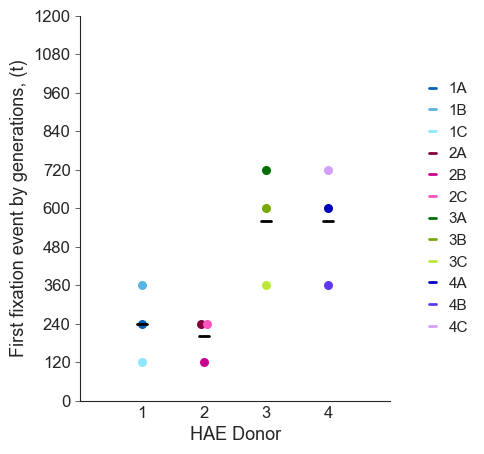

In [17]:

fig, ax = plt.subplots(1,1, figsize=(4,5))
donor_plot = {1:0.5, 2:1, 3:1.5, 4:2}
step_size=0.05

for donor in first_fixation["donor"].unique():
    df = first_fixation[first_fixation["donor"]==donor]
    for passage in df["passage"].unique():
        sdf = df[df["passage"]==passage]
        x = donor_plot[donor]
        if len(sdf) == 1:
            ax.scatter(x, sdf["passage"].values[0], s=30, color=population_cpal[populations.index(sdf["population"].values[0])])
        else:
            spread = (step_size)/2
            print (spread)
            x = x-spread
            for i, row in sdf.iterrows():
                ax.scatter(x, sdf["passage"].values[0], s=30, color=population_cpal[populations.index(row["population"])])
                x+= step_size
   
df = first_fixation.groupby("donor")[["passage"]].mean()
for donor, row in df.iterrows():
    ax.plot([donor_plot[donor]-0.04, donor_plot[donor]+0.04], [row["passage"], row["passage"]],color="black", lw=2)
    
ax.set_xlim(0, 2.5)     
ax.set_xticks([0.5, 1, 1.5, 2])
ax.set_xticklabels([1,2,3,4], size=12)
ax.set_ylabel("First fixation event by generations, (t)", size=13)
ax.set_xlabel("HAE Donor", size=13)

ax.set_yticks(passages)
ax.set_yticklabels([int((p*hours_per_passage)/generation_time)  for p in passages], size=12)

ax.spines[['top','right']].set_visible(False)
ax.tick_params(axis='x', which='both', length=0) 
      
leg = ax.legend(handles=population_legend_elements, loc='center left',  bbox_to_anchor=(1.08,0.5), 
              ncols =1, fontsize=11, handlelength=0.5, edgecolor=None, frameon=False,  columnspacing=0.5) 
   
fig.savefig("../figures/figE2_timing_first_fixation.svg", dpi=300,bbox_inches='tight')
fig.savefig("../figures/figE2_timing_first_fixation.png", dpi=300,bbox_inches='tight') 

**Extended data Figure 2 Timing of first fixation event per HAE donor.** Coloured points represent the independent experimental population. Horizonal black bars indicated the donor mean timing of the first fixation event. 

## 2.6 obtain final dataframes

In [18]:
HMM_states.to_csv("../results/HMM_states_snv_trajectories.csv")
snv_observations.to_csv("../results/snv_observation_timepoints.csv")